# Olist reviews: TF-IDF + logistic regression baseline

Part 2. A fast, cheap, interpretable baseline that sets the bar for the fine-tuned transformer.
If BERTimbau cannot clearly beat a model that trains in seconds on a CPU, its extra cost is not justified.

- **Features:** TF-IDF over words and word pairs (bigrams).
- **Classifier:** multinomial logistic regression.
- **Protocol:** hyperparameters chosen on validation; the test set is scored once.
- **Metric:** macro-F1 (neutral is ~9% of reviews).

**Input:** notebook 1 (*Add Input → Your Work*).

## Setup

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline

SEED = 42
LABELS = ["negative", "neutral", "positive"]  # same order as label_id in notebook 1

OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

## Load the split

In [2]:
INPUT_DIR = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path(".")
validation_file = next(INPUT_DIR.rglob("validation.csv"), None)

if validation_file is None:
    raise FileNotFoundError(
        "validation.csv not found. Add notebook 1 with 'Add Input -> Your Work' in the right-hand panel."
    )

DATA_DIR = validation_file.parent
print("Reading from:", DATA_DIR)

train = pd.read_csv(DATA_DIR / "train.csv", keep_default_na=False)
validation = pd.read_csv(DATA_DIR / "validation.csv", keep_default_na=False)
test = pd.read_csv(DATA_DIR / "test.csv", keep_default_na=False)

for name, part in {"train": train, "validation": validation, "test": test}.items():
    print(f"{name:>10}: {len(part):>6,} reviews")

train.head()

Reading from: /kaggle/input/notebooks/patrickjunmiyauraihy/olist-reviews-data-preparation-and-split
     train: 29,175 reviews
validation:  3,647 reviews
      test:  3,647 reviews


,review_id,text,review_score,label,label_id
0,f00d1a5867e9cb7ce45bf14a6e7a84af,Recomendo a todos podem compra sem medo garant...,5,positive,2
1,f28b2d3524f86a0501189aab29bbd7b5,"O produto não foi entregue, houve a necessidad...",1,negative,0
2,adc6c652114cbbfb70b01aa23f2995e6,Recebi os itens hoje em uma caixa toda rasgada...,1,negative,0
3,c6ce268acedc4acc330c48fda376b3ef,Comprei 8 toalhas pois cada uma seria de uma p...,1,negative,0
4,80ae241edf0e341c3be8d1e500d9083a,"Adorei , foi exatamente oque eu esperava.",5,positive,2


In [3]:
X_train, y_train = train["text"], train["label"]
X_val, y_val = validation["text"], validation["label"]
X_test, y_test = test["text"], test["label"]

print(y_train.value_counts(normalize=True).reindex(LABELS).round(3))

label
negative    0.286
neutral     0.089
positive    0.625
Name: proportion, dtype: float64


## Floor: majority class

A model that always predicts "positive". Any useful model must beat it by a wide margin on macro-F1.

In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_val)

print(f"Accuracy: {accuracy_score(y_val, dummy_pred):.3f}")
print(f"Macro-F1: {f1_score(y_val, dummy_pred, average='macro'):.3f}")

Accuracy: 0.625
Macro-F1: 0.256


## Default model

`sublinear_tf` dampens repeated words; `min_df=2` drops terms seen in a single review (mostly typos).

In [5]:
def make_pipeline(**params) -> Pipeline:
    # Build a fresh TF-IDF + logistic regression pipeline with the given settings.
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, sublinear_tf=True, min_df=2)),
        ("clf", LogisticRegression(max_iter=2000, random_state=SEED)),
    ])
    return pipe.set_params(**params)


start = time.perf_counter()
default_model = make_pipeline().fit(X_train, y_train)
print(f"Training time: {time.perf_counter() - start:.1f} s")

val_pred = default_model.predict(X_val)
print(f"Validation macro-F1: {f1_score(y_val, val_pred, average='macro'):.3f}")
print(classification_report(y_val, val_pred, labels=LABELS, digits=3))

Training time: 5.2 s
Validation macro-F1: 0.625
              precision    recall  f1-score   support

    negative      0.781     0.887     0.830      1043
     neutral      0.362     0.077     0.127       326
    positive      0.897     0.942     0.919      2278

    accuracy                          0.849      3647
   macro avg      0.680     0.635     0.625      3647
weighted avg      0.816     0.849     0.823      3647



## Tuning on validation

Grid of 16 models:
- `ngram_range`: unigrams vs. unigrams + bigrams (captures negations such as "não recomendo");
- `C`: inverse regularization strength;
- `class_weight`: `None` vs. `"balanced"` (up-weights rare classes, usually lifting neutral recall).

In [6]:
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.5, 1, 2, 4],
    "clf__class_weight": [None, "balanced"],
}

results = []
for params in ParameterGrid(param_grid):
    start = time.perf_counter()
    model = make_pipeline(**params).fit(X_train, y_train)
    seconds = time.perf_counter() - start
    pred = model.predict(X_val)
    results.append({
        **params,
        "val_macro_f1": f1_score(y_val, pred, average="macro"),
        "val_neutral_f1": f1_score(y_val, pred, labels=["neutral"], average="macro"),
        "train_seconds": round(seconds, 1),
        "params": params,  # the original dict, kept to rebuild the best model exactly
    })

results = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
results.drop(columns="params").round(3).head(10)

,clf__C,clf__class_weight,tfidf__ngram_range,val_macro_f1,val_neutral_f1,train_seconds
3,0.5,balanced,"(1, 2)",0.680,0.330,6.7
7,1.0,balanced,"(1, 2)",0.677,0.318,10.5
11,2.0,balanced,"(1, 2)",0.675,0.310,11.5
2,0.5,balanced,"(1, 1)",0.673,0.334,4.0
6,1.0,balanced,"(1, 1)",0.669,0.322,5.1
15,4.0,balanced,"(1, 2)",0.668,0.293,13.4
10,2.0,balanced,"(1, 1)",0.661,0.305,6.8
14,4.0,balanced,"(1, 1)",0.652,0.286,6.4
13,4.0,None,"(1, 2)",0.646,0.192,14.2
9,2.0,None,"(1, 2)",0.642,0.170,7.8


In [7]:
best = results.iloc[0]
best_params = best["params"]
print("Best settings:", best_params)
print(f"Validation macro-F1: {best['val_macro_f1']:.3f}")

Best settings: {'clf__C': 0.5, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}
Validation macro-F1: 0.680


The best parameters are read from the stored dict rather than the DataFrame, because pandas turns `None` into `NaN`.

## Final model and test evaluation

Trained on train only (the same data BERTimbau sees) and scored on test once.

In [8]:
final_model = make_pipeline(**best_params)

start = time.perf_counter()
final_model.fit(X_train, y_train)
train_seconds = time.perf_counter() - start

test_pred = final_model.predict(X_test)
test_macro_f1 = f1_score(y_test, test_pred, average="macro")
test_accuracy = accuracy_score(y_test, test_pred)

print(f"Test macro-F1: {test_macro_f1:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print()
print(classification_report(y_test, test_pred, labels=LABELS, digits=3))

Test macro-F1: 0.661
Test accuracy: 0.790

              precision    recall  f1-score   support

    negative      0.768     0.813     0.790      1043
     neutral      0.240     0.404     0.301       327
    positive      0.955     0.835     0.891      2277

    accuracy                          0.790      3647
   macro avg      0.654     0.684     0.661      3647
weighted avg      0.837     0.790     0.809      3647



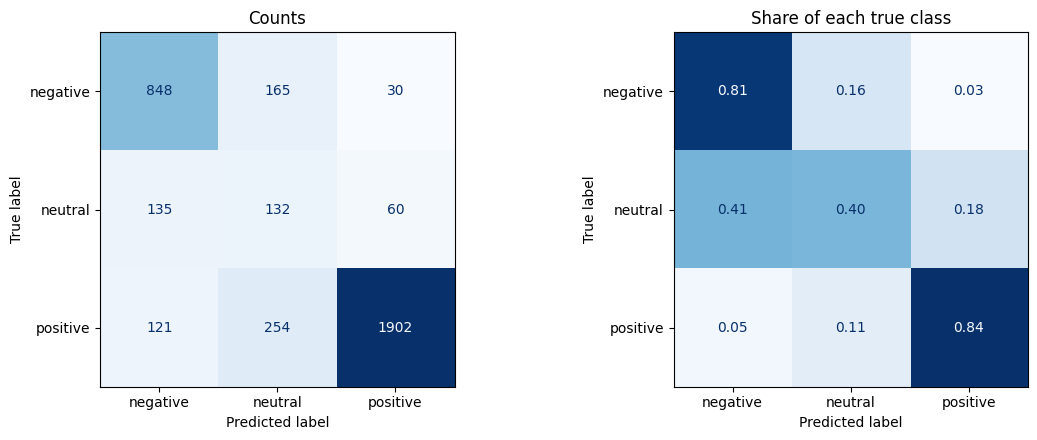

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, normalize, title in [(axes[0], None, "Counts"), (axes[1], "true", "Share of each true class")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred, labels=LABELS, normalize=normalize,
        values_format=".2f" if normalize else "d", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(title)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baseline_confusion_matrix.png", dpi=150)
plt.show()

## What the model learned

Top-weighted terms per class.

In [10]:
vocab = final_model.named_steps["tfidf"].get_feature_names_out()
clf = final_model.named_steps["clf"]
print(f"Vocabulary size: {len(vocab):,} words and word pairs\n")

for class_index, label in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[class_index])[::-1][:15]
    print(f"{label:>8}: " + ", ".join(vocab[top]))

Vocabulary size: 33,006 words and word pairs

negative: não, não recomendo, nao, comprei, péssimo, nem, péssima, quero, produto não, paguei, diferente, ruim, nunca, dinheiro, não gostei
 neutral: porém, mas, bom, porem, ótimo muito, alguns, poderia, veio, amassado, foi rapida, mais, talvez, prazo fiquei, do produto, esperava mais
positive: excelente, recomendo, ótimo, parabéns, antes, adorei, perfeito, tudo, super, lindo, rápido, antes do, amei, ótima, rápida


## Error analysis

Many remaining errors are reviews whose text and star rating disagree (label noise), which caps the achievable score.

In [11]:
errors = test.assign(predicted=test_pred).query("label != predicted")
print(f"{len(errors):,} errors out of {len(test):,} test reviews\n")

for label in LABELS:
    sample = errors[errors["label"] == label].sample(
        min(4, (errors["label"] == label).sum()), random_state=SEED
    )
    for row in sample.itertuples():
        print(f"[true={row.label} | predicted={row.predicted} | {row.review_score} stars] {row.text[:160]}")
    print()

765 errors out of 3,647 test reviews

[true=negative | predicted=neutral | 2 stars] TAPETE MUITO FINO, E PELOS FINOS
[true=negative | predicted=positive | 1 stars] Quando os produtos eram vendidos e entregues pela própria Lojas lannister, chegavam sempre antes do prazo e sem problemas.
[true=negative | predicted=neutral | 1 stars] Boa tarde,qdo comprei era cartucho hp 933XL original e veio cartucho desconhecido com tinta. No anuncio nao deveriam colocar a embalagem do produto,pois pela fo
[true=negative | predicted=neutral | 1 stars] Comprei um jogo de mantimentos no.prazo.perfeito mas as vasilhas estão todas manchadas por dentro e não tem como.fica e lavando.pois o desenho de fora e adesivo

[true=neutral | predicted=positive | 3 stars] gostei só achei pequena.
[true=neutral | predicted=negative | 3 stars] Não Recomendo. Os frascos do produto vieram com manchas escuras, com uma apresentação de falta de cuidado no armazenamento.
[true=neutral | predicted=negative | 3 stars] nao ecebi p

## Cost and latency (CPU)

Training time, single-review latency (median of 200 calls), batch throughput and model size.

In [12]:
MODEL_PATH = OUTPUT_DIR / "tfidf_logreg.joblib"
joblib.dump(final_model, MODEL_PATH)
model_mb = MODEL_PATH.stat().st_size / 1e6

start = time.perf_counter()
final_model.predict(X_test)
batch_seconds = time.perf_counter() - start

single = [X_test.iloc[0]]
timings = []
for _ in range(200):
    start = time.perf_counter()
    final_model.predict(single)
    timings.append(time.perf_counter() - start)
single_ms = float(np.median(timings) * 1000)

print(f"Training time (CPU):          {train_seconds:.1f} s")
print(f"Predict whole test set:       {batch_seconds:.2f} s ({len(X_test) / batch_seconds:,.0f} reviews/s)")
print(f"Latency, one review (median): {single_ms:.2f} ms")
print(f"Model file size:              {model_mb:.1f} MB")

Training time (CPU):          6.6 s
Predict whole test set:       0.09 s (39,158 reviews/s)
Latency, one review (median): 1.14 ms
Model file size:              1.6 MB


## Save metrics

Written to `baseline_metrics.json`. The BERTimbau notebook writes the same keys so the comparison table is built from both files.

In [13]:
report = classification_report(y_test, test_pred, labels=LABELS, output_dict=True)

metrics = {
    "model": "tfidf_logreg",
    "best_params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_params.items()},
    "validation_macro_f1": round(float(best["val_macro_f1"]), 4),
    "test_macro_f1": round(float(test_macro_f1), 4),
    "test_accuracy": round(float(test_accuracy), 4),
    "test_per_class": {
        label: {m: round(float(report[label][m]), 4) for m in ["precision", "recall", "f1-score"]}
        for label in LABELS
    },
    "majority_class_val_macro_f1": round(float(f1_score(y_val, dummy_pred, average="macro")), 4),
    "train_seconds_cpu": round(train_seconds, 2),
    "latency_ms_single_cpu": round(single_ms, 3),
    "throughput_reviews_per_s_cpu": round(len(X_test) / batch_seconds),
    "model_size_mb": round(model_mb, 2),
    "n_train": len(train),
    "n_test": len(test),
}

with open(OUTPUT_DIR / "baseline_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))

{
  "model": "tfidf_logreg",
  "best_params": {
    "clf__C": 0.5,
    "clf__class_weight": "balanced",
    "tfidf__ngram_range": [
      1,
      2
    ]
  },
  "validation_macro_f1": 0.6795,
  "test_macro_f1": 0.6606,
  "test_accuracy": 0.7902,
  "test_per_class": {
    "negative": {
      "precision": 0.7681,
      "recall": 0.813,
      "f1-score": 0.7899
    },
    "neutral": {
      "precision": 0.2396,
      "recall": 0.4037,
      "f1-score": 0.3007
    },
    "positive": {
      "precision": 0.9548,
      "recall": 0.8353,
      "f1-score": 0.8911
    }
  },
  "majority_class_val_macro_f1": 0.2563,
  "train_seconds_cpu": 6.63,
  "latency_ms_single_cpu": 1.141,
  "throughput_reviews_per_s_cpu": 39158,
  "model_size_mb": 1.61,
  "n_train": 29175,
  "n_test": 3647
}


## Data and license

Olist, *Brazilian E-Commerce Public Dataset by Olist*, Kaggle, CC BY-NC-SA 4.0.